# Classification Analysis
**Part A:** SVM for handwritten digit recognition  |  **Part B:** KNN on the Social Network Ads dataset

## Part A: SVM on Handwritten Digits (0 to 9)
The digits dataset (1,797 images of 8x8 pixels) is loaded directly from scikit-learn, so no download is needed.

Images: 1797 | Pixels per image: 64 | Classes: [0 1 2 3 4 5 6 7 8 9]


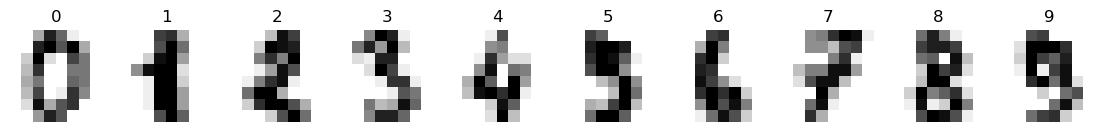

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

digits = load_digits()
X, y = digits.data, digits.target
print("Images:", X.shape[0], "| Pixels per image:", X.shape[1], "| Classes:", np.unique(y))

fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for ax, img, label in zip(axes, digits.images, y):
    ax.imshow(img, cmap="gray_r"); ax.set_title(label); ax.axis("off")
plt.show()

Test accuracy: 99.44%

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      1.00      0.99        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       1.00      1.00      1.00        36
           5       1.00      1.00      1.00        37
           6       1.00      1.00      1.00        36
           7       0.97      1.00      0.99        36
           8       1.00      0.97      0.99        35
           9       1.00      0.97      0.99        36

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



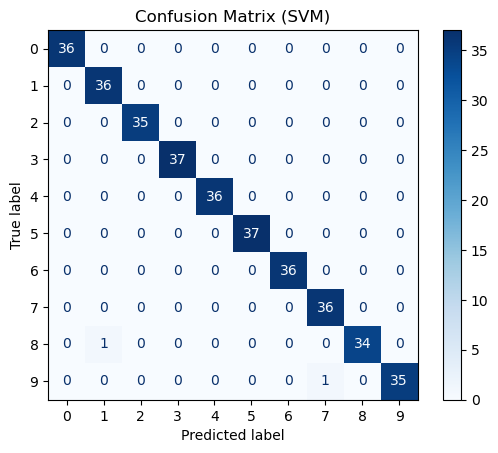

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

svm = SVC(kernel="rbf", gamma="scale", C=10).fit(X_train, y_train)
pred = svm.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, pred):.2%}\n")
print(classification_report(y_test, pred))

ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap="Blues")
plt.title("Confusion Matrix (SVM)")
plt.show()

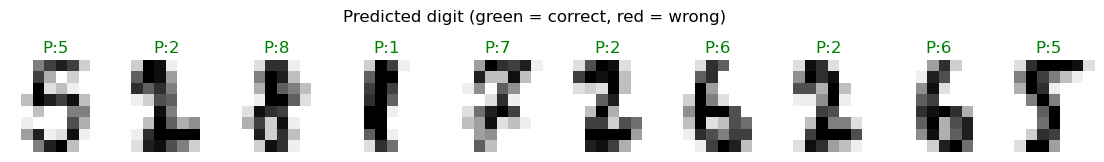

In [3]:
# Sample test predictions
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for ax, img, p, t in zip(axes, X_test[:10], pred[:10], y_test[:10]):
    ax.imshow(img.reshape(8, 8), cmap="gray_r"); ax.axis("off")
    ax.set_title(f"P:{p}", color="green" if p == t else "red")
plt.suptitle("Predicted digit (green = correct, red = wrong)")
plt.show()

**Conclusion:** the RBF-kernel SVM classifies handwritten digits with very high accuracy; the confusion matrix shows only a few misclassified images.

## Part B: KNN on Social Network Ads Dataset
The dataset is downloaded from Kaggle with `kagglehub`. Predict whether a user purchased the product (`Purchased`) from `Age` and `EstimatedSalary`.

In [4]:
%pip install -q kagglehub

Note: you may need to restart the kernel to use updated packages.


In [5]:
import glob, os
import kagglehub

path = kagglehub.dataset_download("rakeshrau/social-network-ads")
df = pd.read_csv(glob.glob(os.path.join(path, "*.csv"))[0])
print(df.shape, "| missing values:", df.isnull().sum().sum())
print(df["Purchased"].value_counts())
df.head()

(400, 5) | missing values: 0
Purchased
0    257
1    143
Name: count, dtype: int64


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


**Prepare the data and choose K** using 5-fold cross-validation on the training set (features are scaled because KNN is distance-based).

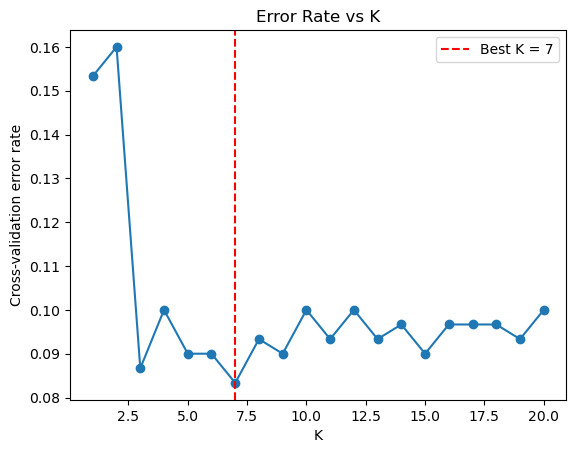

In [6]:
Xb, yb = df[["Age", "EstimatedSalary"]], df["Purchased"]
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=0.25, random_state=0, stratify=yb)

scaler = StandardScaler().fit(Xb_train)
Xb_train, Xb_test = scaler.transform(Xb_train), scaler.transform(Xb_test)

ks = range(1, 21)
errors = [1 - cross_val_score(KNeighborsClassifier(k), Xb_train, yb_train, cv=5).mean() for k in ks]
best_k = ks[int(np.argmin(errors))]

plt.plot(ks, errors, marker="o")
plt.axvline(best_k, color="red", ls="--", label=f"Best K = {best_k}")
plt.title("Error Rate vs K"); plt.xlabel("K"); plt.ylabel("Cross-validation error rate"); plt.legend()
plt.show()

**Train KNN and compute the evaluation metrics.**

Accuracy   : 89.00%
Error rate : 11.00%
Precision  : 82.05%
Recall     : 88.89%


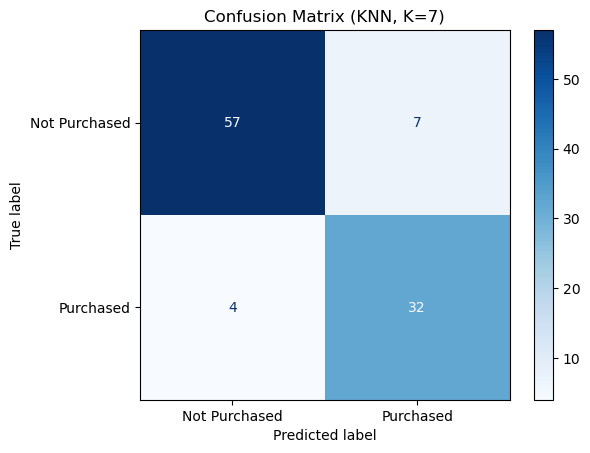

In [7]:
knn = KNeighborsClassifier(n_neighbors=best_k).fit(Xb_train, yb_train)
pred_b = knn.predict(Xb_test)

acc = accuracy_score(yb_test, pred_b)
print(f"Accuracy   : {acc:.2%}")
print(f"Error rate : {1 - acc:.2%}")
print(f"Precision  : {precision_score(yb_test, pred_b):.2%}")
print(f"Recall     : {recall_score(yb_test, pred_b):.2%}")

ConfusionMatrixDisplay.from_predictions(yb_test, pred_b, display_labels=["Not Purchased", "Purchased"], cmap="Blues")
plt.title(f"Confusion Matrix (KNN, K={best_k})")
plt.show()

**Conclusion:** KNN predicts purchases from age and salary with good accuracy. Precision is the share of predicted buyers who actually bought, and recall is the share of actual buyers the model found.